# 04. Error analysis

Errors of the best model (LogReg balanced, words + chars) on the test set. The test set was not used to choose the model, so its errors are a fair picture. Data comes from `make error-analysis`.

In [1]:
import joblib
import pandas as pd
from IPython.display import Image

from itg_classification.config import (
    BEST_MODEL_PATH,
    FIGURES_DIR,
    LABELS,
    PROCESSED_DATA_PATH,
    TEST_PATH,
    TRAIN_PATH,
)
from itg_classification.eda import TEXT_PATTERNS, conflicting_texts
from itg_classification.error_analysis import (
    confidence_table,
    error_examples,
    error_types,
    errors,
    failure_masks,
    failure_table,
    predictions_frame,
    source_table,
    ticker_agreement,
    word_label_shares,
)
from itg_classification.load_data import load_dataset
from itg_classification.split import load_split

pd.set_option("display.max_colwidth", 200)

## 1. Wrong predictions

In [2]:
model = joblib.load(BEST_MODEL_PATH)
frame = predictions_frame(model, load_split(TEST_PATH))
wrong = errors(frame)
len(wrong), len(frame)

(177, 961)

In [3]:
error_types(frame).round(3)

,label,predicted,errors,share_of_errors
0,positive,neutral,68,0.384
1,neutral,positive,49,0.277
2,positive,negative,25,0.141
3,negative,positive,19,0.107
4,neutral,negative,10,0.056
5,negative,neutral,6,0.034


Two thirds of the errors are on the `positive` / `neutral` border (68 + 49). The `negative` / `neutral` border, expected to be the hardest on day 1, gives only 16: dropping the conflicting labels on day 2 cleaned it.

## 2. Confusion matrices and confidence

In [4]:
source_table(frame).round(3)

,texts,errors,error_rate,share_of_errors
source,,,,
news,810,136,0.168,0.768
tweet,151,41,0.272,0.232


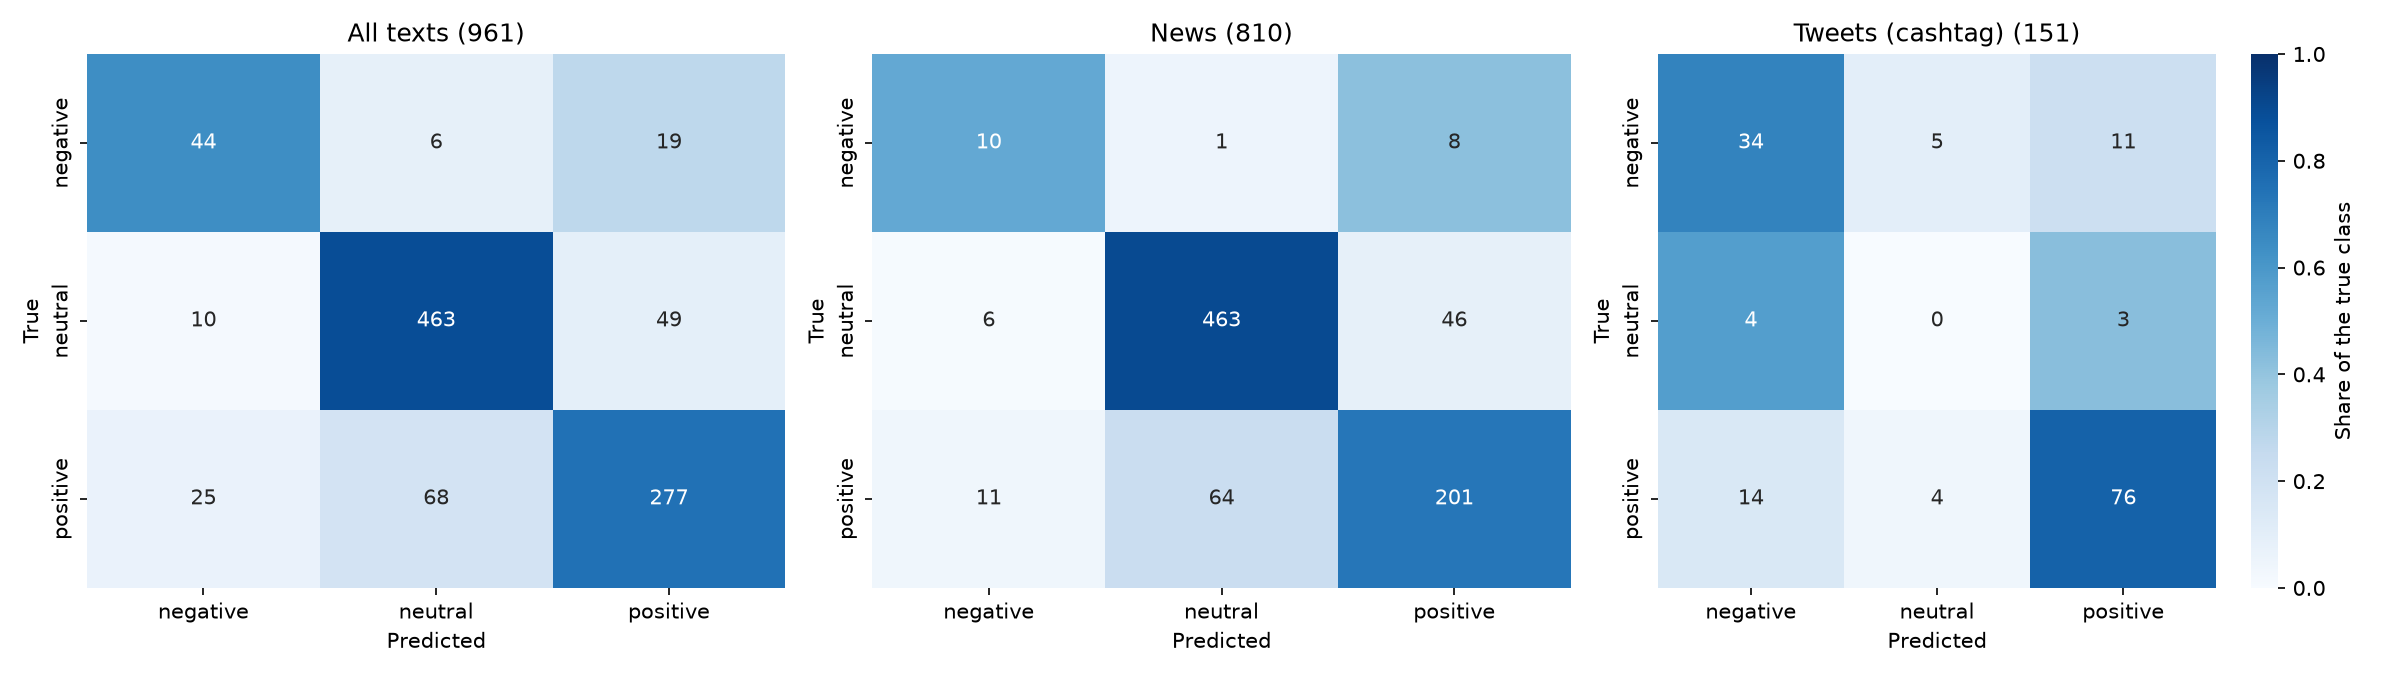

In [5]:
Image(FIGURES_DIR / "confusion_by_source.png")

- **News:** 110 of 136 errors are `positive` ↔ `neutral`. Of 19 `negative` news, 8 go to `positive`.
- **Tweets:** none of the 7 `neutral` tweets is right, the model barely knows neutral tweets. The main confusion is `negative` ↔ `positive` (25 of 41), almost absent in news.

In [6]:
confidence_table(frame).round(3)

,texts,accuracy
confidence,,
"(0.0, 0.5]",82,0.415
"(0.5, 0.6]",173,0.647
"(0.6, 0.7]",151,0.808
"(0.7, 0.8]",175,0.891
"(0.8, 0.9]",251,0.924
"(0.9, 1.0]",129,0.992


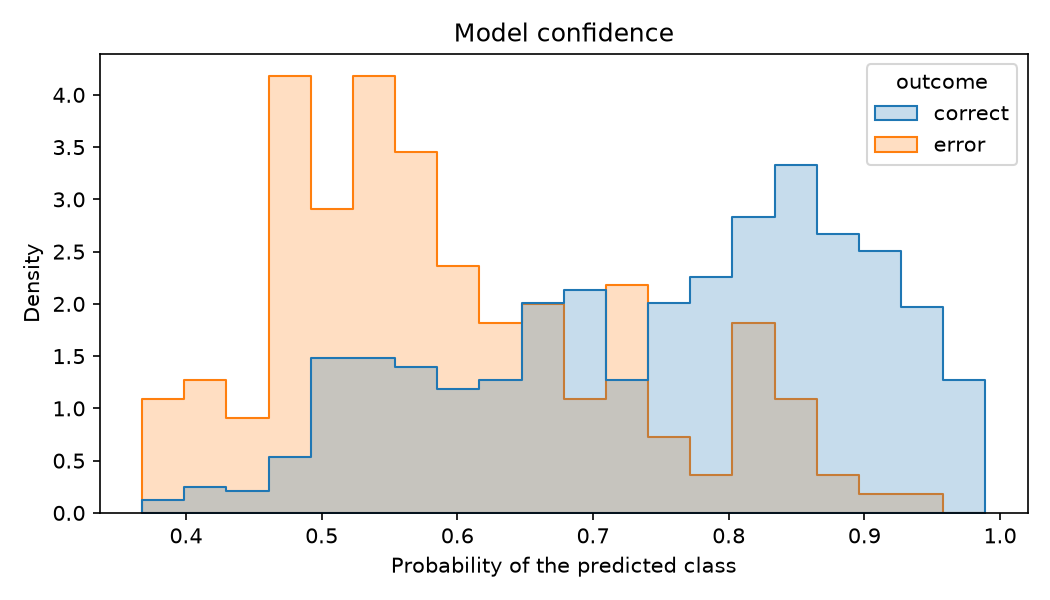

In [7]:
Image(FIGURES_DIR / "confidence.png")

Confidence is meaningful: above 0.9 the model is right 99% of the time, at 0.5 or below only 42%. Errors cluster at 0.45-0.6. A small group of errors is confident (0.8+): either the model learned something wrong, or the label is doubtful.

## 3. Examples of every kind of error

For each kind: the most confident errors first, then the borderline ones. Original texts, before preprocessing.

In [8]:
examples = error_examples(frame, n=5)

### positive → neutral

In [9]:
examples[examples["error"] == "positive → neutral"]

,error,kind,confidence,source,raw_text
0,positive → neutral,confident,0.930715,news,The solutions will be used for upgrading the networks of a Russian MSO in 37 different cities in Russia .
1,positive → neutral,confident,0.890408,news,The company will also be compensated for acting as a reserve batch plant .
2,positive → neutral,confident,0.878384,news,It will combine and renew the contents and functionality of the current systems for funding and online service as well as their maintenance .
3,positive → neutral,confident,0.863144,news,"The negotiations were carried out in a constructive manner , and all parties tried to find a solution to the situation ."
4,positive → neutral,confident,0.856330,news,"SRV will raise its holding in the company so that by the summer of 2008 , it will have a majority ."
5,positive → neutral,borderline,0.449277,news,Industry NewsWolseley confident in reslilience amid mixed markets
6,positive → neutral,borderline,0.472111,tweet,"$CSX is up today to report. Wall Street is expecting EPS to be at $0.37, and revenues at $2,732B."
7,positive → neutral,borderline,0.481106,news,- I am pleased that Bjorn Wahlroos has accepted the nomination .
8,positive → neutral,borderline,0.482001,tweet,"$IMRS - it's important to be pragmatic in analysis...high prices could offer head-winds....bullish story intact,evenif the market rolls over"
9,positive → neutral,borderline,0.487533,news,"By combining its existing solutions into a single platform , Comptel said that it has reduced the cost of deployment ."


The largest kind. The confident ones are news about ordinary business events: a network upgrade, a joint venture, raising a holding. They are labeled `positive` because the event is good for the company, but nothing in the wording says so. Several labels are debatable, the model's `neutral` is a fair reading.

### positive → negative

In [10]:
examples[examples["error"] == "positive → negative"]

,error,kind,confidence,source,raw_text
10,positive → negative,confident,0.896034,tweet,$FIO won't stay down
11,positive → negative,confident,0.827035,tweet,$JNK http://stks.co/2Fcm Does not want to go down... risk appetite still high
12,positive → negative,confident,0.796817,tweet,@ACInvestorBlog: $SPY eod run :)
13,positive → negative,confident,0.724682,news,Tesco leads leap in FTSE 100; Marks & Spencer drops
14,positive → negative,confident,0.717282,tweet,"$CNP Sell Short Position on CNP,...Closed for Profit $ 59,367.00 (7.75%) http://stks.co/ghjc"
15,positive → negative,borderline,0.377212,news,"PRESS: Serco Set To Appoint Roy Gardner, Ex-Centrica, As Chairman - FT"
16,positive → negative,borderline,0.389063,news,Insight hires Aviva's David Hillier for multi-asset team
17,positive → negative,borderline,0.405109,tweet,$LSCC Accumulation chart continues to make new highs showing accumulation continuing to take place http://stks.co/aDpO
18,positive → negative,borderline,0.446874,news,Standard Life share price: Insurer buys advice firm Pearson Jones
19,positive → negative,borderline,0.458752,tweet,$MA http://stks.co/1CYN continues to consolidate / base here


Mostly tweets with **negated negative words**: *won't stay down*, *does not want to go down*. The model sees `down` and ignores the negation. Also trading jargon: *Sell Short ... Closed for Profit* is a gain, but `short` is the second strongest `negative` feature.

### neutral → positive

In [11]:
examples[examples["error"] == "neutral → positive"]

,error,kind,confidence,source,raw_text
20,neutral → positive,confident,0.860509,tweet,$ENDP Was looking for a long entry but today's price action wasn't appealing
21,neutral → positive,confident,0.827473,news,Sales were down 14 per cent in Finland and up 27 per cent abroad where sales were lifted by the strong growth in sales in Russia and Lithuania .
22,neutral → positive,confident,0.815085,news,"Despite sales growth, UK's Tesco cautions recovery to be bumpy"
23,neutral → positive,confident,0.766553,news,Finnish Bank of +àland will launch its long-term pension savings account at the beginning of June 2010 .
24,neutral → positive,confident,0.752267,news,"In November , the Finnish government decreased its ownership in the company further to 31.1 percent from 38 percent ."
25,neutral → positive,borderline,0.389288,news,"Founded in 2000 , BioView automates laboratory tests , especially diagnostic tests for cancer ."
26,neutral → positive,borderline,0.427494,news,"Previously , it projected the figure to be slightly lower than in 2009 ."
27,neutral → positive,borderline,0.438173,news,"According to Chairman Michael Hornborg , the organizations has merely criticised Raisio 's weak performance ."
28,neutral → positive,borderline,0.468496,news,"`` That 's a very high figure on the European scale , '' Noop said , recalling however that this also includes beer bought by Finnish tourists ."
29,neutral → positive,borderline,0.468717,news,Rihko started to manage Raisio 's Benecol business in summer 2006 after heading tobacco company Altadis ' European operations .


**Mixed sentences**: *sales were down 14% in Finland and up 27% abroad*, *despite sales growth ... cautions*. Positive words win, while the label weighs the whole sentence. Some confident ones look mislabeled, like *decreased its ownership*.

### negative → positive

In [12]:
examples[examples["error"] == "negative → positive"]

,error,kind,confidence,source,raw_text
30,negative → positive,confident,0.735083,tweet,$RNN More bleeding Monday.
31,negative → positive,confident,0.730294,tweet,$XLB the weakest sector this year and possible false breakout http://stks.co/dL1Z
32,negative → positive,confident,0.712056,tweet,$ENDP being sued by FTC.....nobody will buy them with that hanging over their heads
33,negative → positive,confident,0.679907,tweet,what is up with $HK..... from Jan to now it's been a sinking ship...
34,negative → positive,confident,0.625880,tweet,looks like a big feb 18-22 $put spread on $cree. Last quarter 0% YoY rev growth trading @ 24x earnings. I may try a short.
35,negative → positive,borderline,0.390778,tweet,Buyback not trending right ( $CPIX spending more as shares pricier). Hopefully will pull back w 6.87 Q2 closing VWAP
36,negative → positive,borderline,0.438275,news,HSBC Says Unit to Book $585 Million Charge on Settlement
37,negative → positive,borderline,0.461698,news,"Berkshire discloses unit's ties to Iran, opens probe"
38,negative → positive,borderline,0.468576,news,UPDATE 1-Lloyds to cut 945 jobs as part of 3-year restructuring plan
39,negative → positive,borderline,0.473319,tweet,$GRPN might be selling off ahead of $P earnings...


Tweets in **slang and metaphors**: *more bleeding*, *a sinking ship*, *false breakout*. The model does not know these phrases, and the word `up` in *what is up with $HK* pushes to `positive`.

### neutral → negative

In [13]:
examples[examples["error"] == "neutral → negative"]

,error,kind,confidence,source,raw_text
46,neutral → negative,confident,0.556502,tweet,$BABA may take a few days wks months watch what happened to $FB $TWTR after they IPO. mrkt needs to washout. to hunt well need 2 wait stalk.
47,neutral → negative,confident,0.540198,news,"This one was at one time targeted for June 5 , but if we had to guess , it 's been pushed back -- maybe we 're crazy , but we feel like it has n't leaked enough to meet that date at this point ."
48,neutral → negative,confident,0.538318,tweet,$AAPL broke descending channel....will it hold?
49,neutral → negative,confident,0.489007,news,"While I cant understand what theyre saying , its impressive to watch him hit that ball at those speeds ."
50,neutral → negative,confident,0.484161,news,Petrofac share price rises despite Â£30m costs on North Sea project
51,neutral → negative,borderline,0.379349,news,CompaniesHoward Davies appointment as RBS director delayed
52,neutral → negative,borderline,0.415754,news,`` This could be us .
53,neutral → negative,borderline,0.421486,news,"Only L+ñnnen Tehtaat showed a loss , but it has only recently started streamlining measures ."
54,neutral → negative,borderline,0.422089,tweet,$NVDA sideways
55,neutral → negative,borderline,0.481224,tweet,Sold some $TSLA Puts this morning Closed them at the close. Helps pay for monthly expenses


Few and unconfident: vague tweets about trading (*broke descending channel ... will it hold?*) and mixed headlines (*share price rises despite £30m costs*).

### negative → neutral

In [14]:
examples[examples["error"] == "negative → neutral"]

,error,kind,confidence,source,raw_text
40,negative → neutral,confident,0.583044,tweet,"Casinos red before the bell: $LVS -0.75%, $WYNN -0.47%, $WYNN -0.47% > unusual comibinations of what's running, what's red before the bell"
41,negative → neutral,confident,0.533108,tweet,Academics claim Google Android two-factor authentication is breakable. #security #authentication #hacking $goog https://t.co/nJx4mnrGLo
42,negative → neutral,confident,0.469789,tweet,$AMD big dumping... would not touch it for a while
43,negative → neutral,confident,0.408128,news,Diageo sales disappoint as currency and comparatives leave bitter taste
44,negative → neutral,confident,0.403301,tweet,$BBRY Actually lost .03c per share if U incl VZ as no debt and 3.1 in Cash.
45,negative → neutral,borderline,0.387770,tweet,$FB I've been dead on so far. Such a bloated valuation. https://t.co/czCf8Kbrlt


Rare. Negative meaning without typical negative words: *sales disappoint*, *bloated valuation*, *lost .03c per share*.

## 4. Failure cases

Hypotheses from the examples, checked on the whole test set.

### 4.1 Text patterns

In [15]:
failure_table(frame, failure_masks(frame)).round(3)

,texts,errors,error_rate,error_rate_without
tweet,151.0,41.0,0.272,0.168
negation,41.0,10.0,0.244,0.182
down words,64.0,16.0,0.250,0.179
up and down words,7.0,2.0,0.286,0.183
number or %,470.0,75.0,0.160,0.208
"short, 6 words or less",45.0,8.0,0.178,0.184


- **Tweets** (27% errors against 17%) and texts with **down words** (25% against 18%) are the clear weak spots.
- **Negation** is worse (24% against 18%), but only 41 texts.
- **Numbers and short texts are not a problem**: their error rate is at or below the rest.
- Mixed **up and down** sentences are hard (2 of 7), but rare.

### 4.2 Memorized tickers

For every ticker, the most common label of its train texts is what the model can memorize. Does the model fail when a test text goes against it?

In [16]:
train = load_split(TRAIN_PATH)
test = load_split(TEST_PATH)
frame["ticker"] = ticker_agreement(test, train)
grouped = frame.groupby("ticker")["correct"]
pd.DataFrame(
    {"texts": grouped.size(), "error_rate": 1 - grouped.mean()}
).round(3)

,texts,error_rate
ticker,,
agrees,55,0.127
disagrees,45,0.378
no ticker,810,0.168
unseen ticker,51,0.333


When the ticker's train label agrees with the true label, tweets have 13% errors. When it disagrees, 38%: the model partly predicts the company's usual sentiment, not the text's. Unseen tickers are also hard (33%): tweets are short and the ticker was a large part of the signal.

### 4.3 Negative news

Why is *Profit fell sharply in the third quarter* `positive`? How are the train texts with falling words labeled:

In [17]:
word_label_shares(
    train,
    ["fell", "decreased", "loss", "lower", "down", "rose", "increased"],
    LABELS,
).round(2)

,texts,negative,neutral,positive
fell,8.0,0.00,0.75,0.25
decreased,8.0,0.00,0.88,0.12
loss,63.0,0.08,0.11,0.81
lower,19.0,0.58,0.26,0.16
down,36.0,0.58,0.19,0.22
rose,79.0,0.01,0.05,0.94
increased,68.0,0.00,0.06,0.94


Not a single train text with `fell` or `decreased` is `negative`, and `loss` is `positive` in 81% of texts (*net loss narrowed*, *compared to a loss of EUR 159 mn*). Where did the negative news go?

In [18]:
raw = load_dataset()
processed = load_split(PROCESSED_DATA_PATH)
conflicts = raw["text"].isin(conflicting_texts(raw).index)


def negative_by_source(texts: pd.Series, labels: pd.Series) -> pd.Series:
    tweet = texts.str.contains(TEXT_PATTERNS["cashtag"])
    negative = labels == "negative"
    return pd.Series(
        {"news": (negative & ~tweet).sum(), "tweets": (negative & tweet).sum()}
    )


pd.DataFrame(
    {
        "raw": negative_by_source(raw["text"], raw["label"]),
        "processed": negative_by_source(
            processed["raw_text"], processed["label"]
        ),
    }
)

,raw,processed
news,642,128
tweets,218,215


In [19]:
raw[conflicts].sort_values("text").head(4)

,text,label
3685,"( ADP News ) - Feb 11 , 2009 - Finnish wood products technology supplier Raute Oyj ( HEL : RUTAV ) said today its net profit decreased to EUR 4.7 million ( USD 6.1 m ) for 2008 from EUR 6.6 millio...",negative
4578,"( ADP News ) - Feb 11 , 2009 - Finnish wood products technology supplier Raute Oyj ( HEL : RUTAV ) said today its net profit decreased to EUR 4.7 million ( USD 6.1 m ) for 2008 from EUR 6.6 millio...",neutral
1488,"( ADP News ) - Feb 12 , 2009 - Finnish construction company Lemminkainen Oyj ( HEL : LEM1S ) said today its net profit decreased to EUR 63.5 million ( USD 81.1 m ) for 2008 from EUR 80.6 million f...",negative
3765,"( ADP News ) - Feb 12 , 2009 - Finnish construction company Lemminkainen Oyj ( HEL : LEM1S ) said today its net profit decreased to EUR 63.5 million ( USD 81.1 m ) for 2008 from EUR 80.6 million f...",neutral


**The root cause is our day 2 decision.** All 1,028 conflicting rows were news like *net profit decreased to EUR 4.7 million*, labeled once `negative` and once `neutral`. Option A dropped them all and with them 514 of 642 negative news, 80%. The model is left with 128 negative news, so it never learned that a falling profit is bad news. The `negative` class it learned is mostly a tweet class.

### 4.4 Doubtful labels

Errors with confidence 0.75 or more, read one by one:

In [20]:
wrong[wrong["confidence"] >= 0.75][
    ["confidence", "label", "predicted", "raw_text"]
].round(2)

,confidence,label,predicted,raw_text
553,0.93,positive,neutral,The solutions will be used for upgrading the networks of a Russian MSO in 37 different cities in Russia .
34,0.90,positive,negative,$FIO won't stay down
647,0.89,positive,neutral,The company will also be compensated for acting as a reserve batch plant .
455,0.88,positive,neutral,It will combine and renew the contents and functionality of the current systems for funding and online service as well as their maintenance .
338,0.86,positive,neutral,"The negotiations were carried out in a constructive manner , and all parties tried to find a solution to the situation ."
253,0.86,neutral,positive,$ENDP Was looking for a long entry but today's price action wasn't appealing
91,0.86,positive,neutral,"SRV will raise its holding in the company so that by the summer of 2008 , it will have a majority ."
317,0.85,positive,neutral,SINGAPORE ( ICIS ) -- ( 1 ) Kemira and Indian water infrastructure firm ( 2 ) IVRCL have agreed to form a join venture which includes a new inorganic coagulant manufacturing facility in Andhra Pra...
745,0.85,positive,neutral,`` The combined activities will create value for shareholders and be good for our employees and customers .
784,0.83,positive,neutral,The group will expand the chain to include 45 stores .


My reading of these 26 confident errors:

| Verdict | Errors | Examples |
|---|---|---|
| The model is wrong | 11 | *won't stay down*, *does not want to go down*, *will create value for shareholders*, *is well positioned*, *fundamentals remain sound* |
| Mixed sentence, both readings fair | 2 | *sales were down 14% in Finland and up 27% abroad*, *despite sales growth ... cautions* |
| Doubtful label, `neutral` is as fair | 13 | *will expand the chain to include 45 stores*, *will raise its holding*, *have agreed to form a joint venture*, *has placed orders for 10 tankers* |

Half of the confident errors are business events labeled `positive` because the event is good for the company, with no evaluative word in the text. Telling them from neutral facts needs knowledge about business, not words, so part of the `positive` → `neutral` errors is a ceiling for any bag-of-words model.

### 4.5 Failure cases, ranked

| # | Failure case | Evidence | Errors it explains |
|---|---|---|---|
| 1 | **Business events without evaluative words** | 13 of 26 confident errors have doubtful labels; `positive` ↔ `neutral` is 117 of 177 errors | the largest share, mostly news |
| 2 | **Almost no negative news in train** | 514 of 642 dropped with the conflicts; `fell`, `decreased` never `negative`, `loss` 81% `positive` | negative news → `positive`, 8 of 19 |
| 3 | **Memorized tickers** | 38% errors when the ticker's usual label disagrees, 13% when it agrees | 17 tweet errors |
| 4 | **Tweet slang and negation** | *more bleeding*, *sinking ship*, *won't stay down*; negation 24% errors against 18% | most of the 25 `negative` ↔ `positive` tweet errors |
| 5 | **Neutral tweets** | 0 of 7 right | 7 errors |

Not failure cases: numbers, percentages and short texts.

## 5. Conclusions and next steps

**Where the model fails**, most errors first:

1. **Business events without evaluative words.** `positive` ↔ `neutral` is 117 of 177 errors. Half of the confident errors have doubtful labels: a contract or an expansion is `positive` because it is good for the company, not because of any word. This is a ceiling for a bag-of-words model.
2. **Almost no negative news in train.** Option A of day 2 dropped 514 of 642 negative news. The model never learned that a falling profit is bad news, and its `negative` class is mostly tweets.
3. **Memorized tickers.** A tweet going against its company's usual sentiment has 38% errors, against 13%.
4. **Tweet slang and negation**: *more bleeding*, *sinking ship*, *won't stay down*.
5. **Neutral tweets**: 0 of 7 right.

Numbers, percentages and short texts are not a problem. The confidence is meaningful: 99% accuracy above 0.9, 42% at 0.5 or below.

**What to improve next**, most promising first:

| # | Idea | Fixes | Effort |
|---|---|---|---|
| 1 | Keep one `negative` copy of every conflicting news text (option B) | negative news | small: one line in preprocessing |
| 2 | Replace every cashtag with one `$ticker` token | memorized and unseen tickers | small |
| 3 | Mark negation scope: *won't stay not_down* | negation | small |
| 4 | Financial sentiment lexicon (Loughran-McDonald) as features | slang, rare words | medium |
| 5 | Contextual model (FinBERT) | business events, mixed sentences | large |
| 6 | Show the confidence at inference, flag predictions below 0.6 | trust in predictions | small, planned for the inference day |

The same analysis as text: `results/error_analysis.txt`.